# Этап 10. Экономическая интерпретация муниципальных кластеров

## 1. Цель и связь с предыдущими этапами

**Задача:** описать содержательные особенности экономических типов, обнаруженных на шагах 07–09, без нового обучения кластеризаторов и без изменения рёбер графа. В основной интерпретации используются **согласованные во времени метки Temporal K-Means** шага 08. Статический K-Means шага 07 служит контрольной моделью, но его несогласованные номера кластеров не сопоставляются напрямую между годами.

Единица анализа — муниципалитет $i$ с постоянным ID; месячный индекс $t\in\{2023\text{-}01,\ldots,2024\text{-}12\}$. Потребительские признаки $X_t$ — шесть долей расходов; годовой контекст $A_{i,y}$ — восемь БДМО за $y=2023,2024$; изменения $\Delta A_i$ — разности годовых уровней. Сведения БДМО **не участвовали** в обучении исходной временной модели, поэтому используются как внешние объясняющие признаки.

В отличие от причинно-прогностической постановки, годовые показатели соответствующего года здесь анализируются **ретроспективно**: значения 2024 года не считаются известными в январе 2024 года.

## 2. Математическое определение профилей и отличительных признаков

Пусть $C_{a,t}=\{i:g_i(t)=a\}$ — множество муниципалитетов экономического типа $a$ в месяце $t$, $n_{a,t}=|C_{a,t}|$. Номер $a$ согласован в рамках сохранённой временной модели, но его значение не определяет экономический смысл типа.

Для категории расходов $p$ сравниваем **среднюю долю** кластера со средним значением выборки, в процентных пунктах:

$$
\overline{s}_{a,p,t}=\frac{1}{n_{a,t}}\sum_{i\in C_{a,t}}s_{i,p,t},\qquad
D^{(s)}_{a,p,t}=100\bigl(\overline{s}_{a,p,t}-\overline{s}_{p,t}\bigr).
$$

Средние доли шести категорий суммируются в единицу. Кроме того, рассчитываются **медиана и квартили**, которые характеризуют неоднородность внутри типа.

Для годового показателя $q$ с пропусками обозначим наблюдаемые муниципалитеты типа как $O_{a,q,y}\subseteq C_{a,t}$. Вычисляем медиану $m_{a,q,y}$ и квартильный интервал $[Q_{.25},Q_{.75}]$ на **наблюдаемых** значениях. Стандартизированное отклонение от общей выборки:

$$
D^{(A)}_{a,q,y}=\frac{m_{a,q,y}-m_{q,y}}{Q_{.75}(A_{q,y})-Q_{.25}(A_{q,y})},
$$

где $m_{q,y}$ и квартили в знаменателе рассчитаны по доступным муниципалитетам **всей** выборки. При нулевом IQR значение не определяется (`NaN`); пропуски не заменяются нулями. Для каждого сравнения показывается доля наблюдений $|O_{a,q,y}|/n_{a,t}$. **$D^{(s)}$ и $D^{(A)}$ имеют разные единицы и не ранжируются совместно.**

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.feature_analysis import SHARES, parse_dynamic_columns
from src.cluster_validation import load_saved_partitions
from src.annual_attribution import INDICATORS, INDICATOR_INFO
from src.economic_interpretation import (
    validate_sources, validate_delta_identity, profile_panel,
    cluster_distinctions, interpretation_candidates, read_municipality_lookup,
    representative_municipalities, snapshot_stability, delta_switch_association,
    retained_delta_by_type, save_tables,
)

cfg = json.loads((ROOT/'configs'/'clustering_experiment.json').read_text(encoding='utf-8'))
icfg = cfg['interpretation_10']
X_dynamic = pd.read_parquet(ROOT/cfg['feature_path'])
X_annual = pd.read_parquet(ROOT/icfg['annual_path'])
X_delta = pd.read_parquet(ROOT/icfg['delta_path'])
mapping = parse_dynamic_columns(X_dynamic)
months = [str(m) for m in sorted({m for m, _ in mapping})]

stage07 = ROOT/cfg['output_directory']
stage08 = ROOT/cfg['temporal_08']['output_directory']
partitions, meta08 = load_saved_partitions(stage07, stage08, X_dynamic.index, months,
                                         include_temporal=True)
if icfg['model'] not in partitions:
    raise FileNotFoundError('Нет согласованных временных меток 08. Сначала сохраните temporal_labels.parquet.')
aligned = partitions[icfg['model']]
validate_sources(X_dynamic, X_annual, X_delta, aligned, months)
print('Модель:', icfg['model'], '| lambda:', meta08['temporal_selected_lambda'])
print('Муниципалитеты:', len(X_dynamic), '| месяцы:', len(months))
print('Матрицы:', X_dynamic.shape, X_annual.shape, X_delta.shape)
print('Кластеры в начале / конце:', aligned.iloc[:,0].nunique(),aligned.iloc[:,-1].nunique())

Модель: temporal_kmeans | lambda: 0.25
Муниципалитеты: 2016 | месяцы: 24
Матрицы: (2016, 144) (2016, 16) (2016, 8)
Кластеры в начале / конце: 4 4


## 3. Контроль годовых данных и формулы изменений

Для каждого показателя сначала проверяем математический контракт

$$\Delta A_{i,q}^{2023\to2024}=A_{i,q,2024}-A_{i,q,2023}.$$

Если исходная реализация `flatten_annual` использовала иной способ изменения, выполнение останавливается: интерпретировать неизвестную величину как абсолютную разность нельзя. Пропуск любого из годовых уровней должен давать пропуск разности. На этапе 10 данные 2024 года не используются для изменения уже сохранённых меток кластеров.

In [2]:
delta_check = validate_delta_identity(X_annual, X_delta)
display(delta_check)
print('Подтверждено:', bool(delta_check.values_equal.all() and delta_check.missingness_equal.all()))

# Фактический словарь БДМО из этапа 04 имеет приоритет над приблизительными единицами в коде.
dictionary_path = ROOT/'outputs'/'bdmo_v3'/'features'/'feature_dictionary.csv'
if dictionary_path.exists():
    dictionary = pd.read_csv(dictionary_path)
    display(dictionary.head(8))
else:
    print('Словарь показателей не найден; единицы измерения требуют сверки с БДМО.')

,indicator,n_checked,missingness_equal,values_equal
0,wage,2001,True,True
1,employment_per_1000,1844,True,True
2,reporting_companies_per_1000,2003,True,True
3,profitable_share,2000,True,True
4,investment_total_per_capita,1834,True,True
5,shop_floor_per_capita,1845,True,True
6,population_density,1990,True,True
7,lit_street_share,1895,True,True


Подтверждено: True


,feature,role,view,source,definition
0,wage,primary,labor,8423007,Уровень оплаты труда дополняет структуру потре...
1,employment_per_1000,primary,labor,8423005,После конверсии единиц / population_mean × 1000
2,reporting_companies_per_1000,primary,business,8090001,После конверсии единиц / population_jan × 1000
3,profitable_share,primary,business,8090008,Доля прибыльных организаций: интенсивность без...
4,investment_total_per_capita,primary,investment,8109001,После конверсии единиц / population_mean × 1
5,shop_floor_per_capita,primary,retail_supply,8002002,После конверсии единиц / population_jan × 1
6,population_density,primary,demography,8112027 / 8006001,Человек на км²: население на 1 января / (площа...
7,lit_street_share,primary,infrastructure,8006003 / 8006007,"Доля освещённой протяжённости улиц, %; вне [0,..."


## 4. Профили экономических типов в 2023 и 2024 годах

Берём декабрьские срезы 2023 и 2024 годов. В таблице `profiles` по каждой категории расходов и годовому показателю сохраняются численность типа, количество доступных значений, медиана, квартильные границы, среднее (если содержательно применимо), общий уровень и стандартизированное отличие.

Это **срезы разных составов** кластеров. Разница между профилями 2023 и 2024 года может отражать одновременно изменение характеристик муниципалитетов и изменение состава типа.

In [3]:
snapshots = [(str(m),int(y)) for m,y in icfg['snapshots']]
profiles = profile_panel(X_dynamic,mapping,X_annual,aligned,snapshots)
assert set(profiles.month) == {m for m,_ in snapshots}
counts = (profiles.query("family == 'consumer_share' and indicator == 'share_food'")
          [['month','cluster','cluster_size']].sort_values(['month','cluster']))
display(counts)
print('Средняя доля покрытия БДМО по кластерам:')
display(profiles.query("family == 'annual_bdmo'").groupby(['month','cluster'])
        .coverage.agg(['min','median']).round(3))
print('Пример 12 записей профиля:')
display(profiles[['month','cluster','family','indicator','median','q25','q75',
                  'coverage','contrast']].head(12).round(3))

,month,cluster,cluster_size
0,2023-12,0,654
1,2023-12,1,481
2,2023-12,2,334
3,2023-12,3,547
56,2024-12,0,651
57,2024-12,1,455
58,2024-12,2,334
59,2024-12,3,576


Средняя доля покрытия БДМО по кластерам:


min  median
month   cluster               
2023-12 0        0.951   0.997
        1        0.786   0.986
        2        0.946   0.997
        3        0.951   0.996
2024-12 0        0.889   0.992
        1        0.758   0.971
        2        0.910   0.993
        3        0.899   0.989

Пример 12 записей профиля:


,month,cluster,family,indicator,median,q25,q75,coverage,contrast
0,2023-12,0,consumer_share,share_food,0.485,0.462,0.507,1.0,3.531
1,2023-12,1,consumer_share,share_food,0.358,0.329,0.390,1.0,-9.072
2,2023-12,2,consumer_share,share_food,0.501,0.478,0.533,1.0,5.554
3,2023-12,3,consumer_share,share_food,0.450,0.428,0.476,1.0,0.364
4,2023-12,0,consumer_share,share_health,0.043,0.039,0.049,1.0,-0.165
5,2023-12,1,consumer_share,share_health,0.051,0.047,0.055,1.0,0.481
6,2023-12,2,consumer_share,share_health,0.046,0.041,0.052,1.0,0.124
7,2023-12,3,consumer_share,share_health,0.043,0.037,0.047,1.0,-0.302
8,2023-12,0,consumer_share,share_marketplace,0.167,0.143,0.190,1.0,1.206
9,2023-12,1,consumer_share,share_marketplace,0.141,0.128,0.157,1.0,-1.628


## 5. Отличительные характеристики и тепловая карта

Тепловая карта показывает $D^{(A)}_{a,q,2024}$ — отклонения медиан БДМО, выраженные в межквартильных размахах всей выборки. Цветовая шкала ограничена интервалом $[-3,3]$ **только при визуализации**, без усечения исходных чисел. Пустая клетка означает недоступный или неопределённый показатель, а не значение ноль.

Отдельно ранжируем отличительные категории расходов по $|D^{(s)}|$ и показатели БДМО по $|D^{(A)}|$ при достаточном количестве наблюдений. Названия типов пока не назначаются.

,cluster,family,indicator,contrast,contrast_unit,coverage,observed
0,0,annual_bdmo,reporting_companies_per_1000,-0.218,median_difference_over_global_IQR,0.995,648
1,0,annual_bdmo,profitable_share,-0.212,median_difference_over_global_IQR,0.994,647
2,0,annual_bdmo,wage,-0.201,median_difference_over_global_IQR,0.986,642
3,0,consumer_share,share_food,3.124,percentage_points_mean,1.000,651
4,0,consumer_share,share_other,-2.770,percentage_points_mean,1.000,651
5,0,consumer_share,share_marketplace,1.804,percentage_points_mean,1.000,651
6,1,annual_bdmo,population_density,19.220,median_difference_over_global_IQR,0.978,445
7,1,annual_bdmo,reporting_companies_per_1000,1.765,median_difference_over_global_IQR,0.998,454
8,1,annual_bdmo,wage,1.466,median_difference_over_global_IQR,0.998,454
9,1,consumer_share,share_food,-8.016,percentage_points_mean,1.000,455


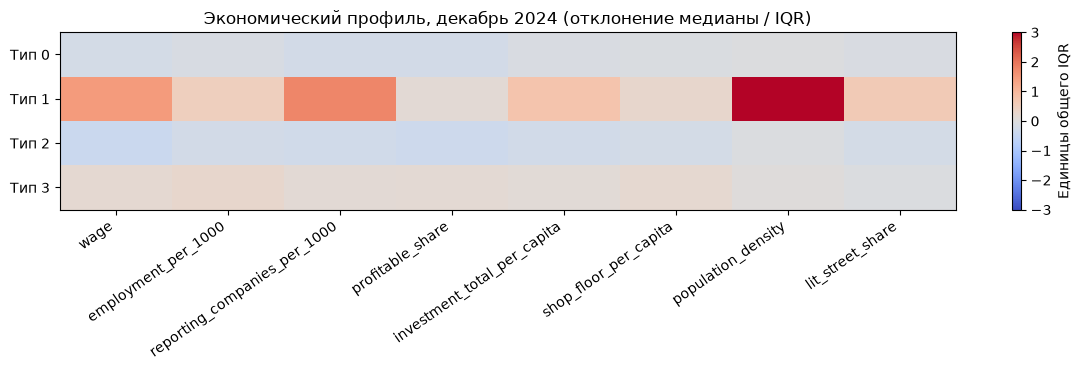

,cluster,month,n_municipalities,provisional_name,consumer_contrasts_pp,annual_contrasts_iqr,interpretation_status
0,0,2024-12,651,Тип 0 — требует экономической интерпретации,share_food: +3.12; share_other: -2.77; share_m...,reporting_companies_per_1000: -0.22; profitabl...,pending_review
1,1,2024-12,455,Тип 1 — требует экономической интерпретации,share_food: -8.02; share_other: +6.11; share_m...,population_density: +19.22; reporting_companie...,pending_review
2,2,2024-12,334,Тип 2 — требует экономической интерпретации,share_other: -5.34; share_food: +4.83; share_m...,wage: -0.38; profitable_share: -0.35; reportin...,pending_review
3,3,2024-12,576,Тип 3 — требует экономической интерпретации,share_other: +1.41; share_marketplace: -1.31; ...,employment_per_1000: +0.27; shop_floor_per_cap...,pending_review


In [4]:
last_month = snapshots[-1][0]
distinctive = cluster_distinctions(profiles,last_month,
    min_observed=icfg['minimum_observed_per_indicator'],
    min_coverage=icfg['minimum_coverage_per_indicator'],
    top_n=icfg['top_distinctive_per_family'])
display(distinctive.round(3))

annual24_profiles = profiles[(profiles.month==last_month)&
                             (profiles.family=='annual_bdmo')]
heat = annual24_profiles.pivot(index='cluster',columns='indicator',values='contrast')
heat = heat.reindex(columns=list(INDICATORS)).sort_index()
fig,ax=plt.subplots(figsize=(12,3.8))
mat=np.ma.masked_invalid(heat.to_numpy(float))
cmap=plt.get_cmap('coolwarm').copy()
cmap.set_bad('lightgrey')
im=ax.imshow(mat,aspect='auto',cmap=cmap,vmin=-3,vmax=3)
ax.set_xticks(np.arange(len(INDICATORS)))
ax.set_xticklabels(INDICATORS,rotation=35,ha='right')
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels([f'Тип {x}' for x in heat.index])
ax.set_title('Экономический профиль, декабрь 2024 (отклонение медианы / IQR)')
fig.colorbar(im,ax=ax,label='Единицы общего IQR')
plt.tight_layout();plt.show()

candidate_types = interpretation_candidates(profiles,last_month)
display(candidate_types)

## 6. Различия по наиболее характерным потребительским и годовым показателям

Отображаем два независимых сравнения: доли расходов в **процентных пунктах** и медианные значения БДМО в **исходных единицах**. Выбираем по два показателя БДМО, имеющих наибольшее среднее абсолютное нормированное отклонение между кластерами, и показываем покрытие данных. Выбор этих показателей — диагностический, не основание автоматически дать типу экономическое название.

Два наиболее контрастных годовых показателя: ['wage', 'reporting_companies_per_1000']


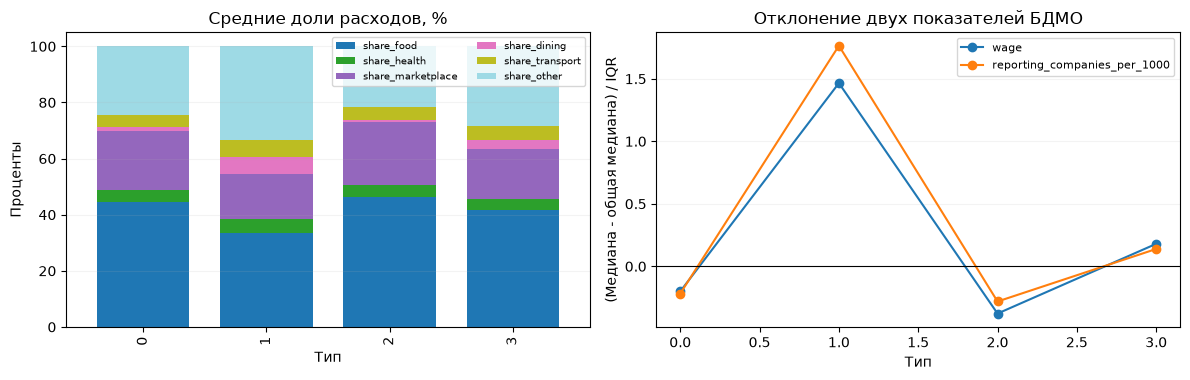

Медианы и покрытие выбранных годовых признаков:


,cluster,indicator,median,q25,q75,coverage
80,0,wage,54364.200,48319.450,62418.650,0.986
81,1,wage,114799.400,85094.925,142786.350,0.998
82,2,wage,47940.300,43732.300,53441.200,0.994
83,3,wage,68169.500,57138.200,83598.400,0.995
88,0,reporting_companies_per_1000,3.769,2.926,5.055,0.995
89,1,reporting_companies_per_1000,15.069,9.988,25.239,0.998
90,2,reporting_companies_per_1000,3.408,2.586,4.584,0.994
91,3,reporting_companies_per_1000,5.802,3.994,8.408,0.995


In [5]:
consumer_24 = profiles[(profiles.month==last_month)&
                               (profiles.family=='consumer_share')]
annual_24 = profiles[(profiles.month==last_month)&(profiles.family=='annual_bdmo')]

chosen_annual = (annual_24.groupby('indicator').contrast
                 .apply(lambda s: s.abs().median()).sort_values(ascending=False)
                 .head(2).index.tolist())
print('Два наиболее контрастных годовых показателя:',chosen_annual)
fig,axes=plt.subplots(1,2,figsize=(12,3.9))
share_plot = consumer_24.pivot(index='cluster',columns='indicator',values='mean')
share_plot = share_plot.reindex(columns=list(SHARES)) * 100
share_plot.plot(kind='bar',stacked=True,ax=axes[0],colormap='tab20',width=.75)
axes[0].set(title='Средние доли расходов, %',xlabel='Тип',ylabel='Проценты')
axes[0].legend(fontsize=7,ncol=2)
if chosen_annual:
    for indicator in chosen_annual:
        sub = annual_24[annual_24.indicator==indicator].sort_values('cluster')
        axes[1].plot(sub.cluster,sub['contrast'],marker='o',label=indicator)
    axes[1].axhline(0,color='black',lw=.8)
    axes[1].legend(fontsize=8)
axes[1].set(title='Отклонение двух показателей БДМО',xlabel='Тип',ylabel='(Медиана - общая медиана) / IQR')
for ax in axes: ax.grid(alpha=.15,axis='y')
plt.tight_layout();plt.show()

print('Медианы и покрытие выбранных годовых признаков:')
display(annual_24.loc[annual_24.indicator.isin(chosen_annual),
                      ['cluster','indicator','median','q25','q75','coverage']].round(3))

## 7. Репрезентативные муниципалитеты и справочник

Типичность муниципалитета определяется евклидовым расстоянием между месячным **CLR-вектором** и средним CLR-вектором его кластера:

$$
\mu_{a,t}^{\mathrm{CLR}}=\frac{1}{n_{a,t}}\sum_{i\in C_{a,t}}\operatorname{clr}(s_{i,t}),\qquad
r_{i,t}=\left\|\operatorname{clr}(s_{i,t})-\mu_{a,t}^{\mathrm{CLR}}\right\|_2.
$$

Сначала выбираем ближайших **среди членов самого кластера**, независимо от пропусков БДМО; затем присоединяем проверенные название и регион по ID. Административный справочник необходимо однозначно сопоставить с индексом $X_{dynamic}$. Если названия или регионы нельзя достоверно установить, таблица примеров **не создаётся**, и требуется явно указать путь к корректному справочнику.

In [6]:
# Формируем проверенных представителей из справочника муниципалитетов 2024.
# Для этого справочника territory_id — ключ модели, а oktmo — другой код.
# Не перехватываем ошибки чтения молча: отсутствие справочника не означает
# отсутствие типичных муниципалитетов и не должно приводить к пустой таблице.
verified_lookup_path = ROOT / 'data' / 'municipality_lookup_2024.csv'
configured_lookup_path = icfg.get('municipality_lookup_path')
lookup_path = (ROOT / configured_lookup_path) if configured_lookup_path else verified_lookup_path

if not lookup_path.is_file() and verified_lookup_path.is_file():
    print('Настроенный справочник не найден; используется проверенный:', verified_lookup_path)
    lookup_path = verified_lookup_path
if not lookup_path.is_file():
    raise FileNotFoundError(
        f'Нет справочника для представителей: {lookup_path}. '
        'Требуется data/municipality_lookup_2024.csv с колонками '
        'territory_id, municipality_name, region.'
    )

# В проверенном справочнике однозначно фиксируем имена колонок,
# даже если в старом конфиге не указаны municipality_*_column.
if lookup_path.name == 'municipality_lookup_2024.csv':
    lookup_columns = dict(id_col='territory_id', name_col='municipality_name', region_col='region')
else:
    lookup_columns = dict(
        id_col=icfg.get('municipality_id_column'),
        name_col=icfg.get('municipality_name_column'),
        region_col=icfg.get('region_column'),
    )

lookup = read_municipality_lookup(lookup_path, X_dynamic.index, **lookup_columns)
examples = representative_municipalities(
    X_dynamic, mapping, aligned, icfg['representatives_month'], lookup, X_annual,
    top_n=icfg['representatives_per_cluster'], zero_floor=cfg['zero_floor'],
)
assert len(examples) == int(aligned[icfg['representatives_month']].nunique()) * int(icfg['representatives_per_cluster'])
display(examples[['municipality_id','municipality_name','region','cluster','rank',
                  'distance_to_clr_centroid','share_food','share_health',
                  'wage','population_density']].round(3))
print('Имена и регионы подтверждены справочником:', lookup_path)


,municipality_id,municipality_name,region,cluster,rank,distance_to_clr_centroid,share_food,share_health,wage,population_density
0,1414,Данковский муниципальный район,Липецкая область,0,1,0.097,0.442,0.043,59157.2,16.631
1,1308,городской округ город Шарья,Костромская область,0,2,0.098,0.454,0.036,55333.6,677.381
2,307,Торбеевский муниципальный район,Республика Мордовия,0,3,0.115,0.465,0.042,53695.6,16.206
3,1581,муниципальный округ Крестецкий,Новгородская область,0,4,0.119,0.450,0.038,70229.5,4.005
4,2546,внутригородская территория города федерального...,Москва,1,1,0.043,0.332,0.049,136813.5,16338.930
5,2467,внутригородская территория города федерального...,Москва,1,2,0.063,0.344,0.049,108689.0,12265.791
6,2466,внутригородская территория города федерального...,Москва,1,3,0.068,0.343,0.049,132274.9,10988.326
7,2469,внутригородская территория города федерального...,Москва,1,4,0.069,0.336,0.048,119476.7,5853.272
8,2156,Кривошеинский муниципальный район,Томская область,2,1,0.111,0.497,0.040,64584.0,2.745
9,1420,Измалковский муниципальный район,Липецкая область,2,2,0.114,0.454,0.046,NaN,NaN


Имена и регионы подтверждены справочником: /Users/olgakan/vlad/hack/data/municipality_lookup_2024.csv


## 8. Устойчивость типов и годовая экономическая динамика

Для каждого типа оценим долю муниципалитетов, сохранивших согласованную метку в следующем месяце:

$$
R_{a,t}=\frac{|\{i\in C_{a,t}:g_i(t+1)=a\}|}{|C_{a,t}|}.
$$

Доля относится к **исходному** типу $a$ и не заменяет ARI/NMI шага 09.

Связь месячных переходов с годовыми изменениями проверяется отдельно. Для $i$ считаем $N_i^{(2024)}=\sum_{t:\,\mathrm{year}(t+1)=2024}\mathbf1\{g_i(t)\ne g_i(t+1)\}$, затем описательно сравниваем его с $\Delta A_{i,q}^{2023\to2024}$. Для этого используются корреляции Спирмена и медианные изменения у муниципалитетов **с переходами и без**. Эти связи нельзя интерпретировать причинно: месячные изменения структуры расходов и годовые показатели наблюдались в пересекающихся периодах.

Дополнительно проверяем изменения среди муниципалитетов, сохранивших тип на двух декабрьских срезах, чтобы уменьшить, но не устранить смешение изменения состава групп и изменения их характеристик.

Устойчивость типов:


,median_stay,worst_month_stay,month_pairs
cluster,,,
0,0.916,0.631,23
1,0.983,0.781,23
2,0.935,0.700,23
3,0.933,0.584,23


Связь переходов с годовыми изменениями:


,indicator,n_available,missing_share,n_switchers,median_delta_switchers,median_delta_non_switchers,spearman_switch_count_delta,spearman_switch_count_abs_delta
0,wage,2001,0.007,743,8872.200,10676.500,-0.200,-0.200
1,employment_per_1000,1844,0.085,663,-0.727,0.028,-0.063,-0.058
2,reporting_companies_per_1000,2003,0.006,740,-0.007,-0.019,0.019,-0.103
3,profitable_share,2000,0.008,742,0.000,-0.300,0.031,0.187
4,investment_total_per_capita,1834,0.090,660,4305.501,6220.333,-0.047,-0.066
5,shop_floor_per_capita,1845,0.085,715,0.010,0.013,-0.066,-0.068
6,population_density,1990,0.013,737,-0.074,-0.092,0.080,-0.279
7,lit_street_share,1895,0.060,740,0.000,0.000,-0.032,0.002


Медианные годовые изменения среди сохраняющих экономический тип:


indicator,employment_per_1000,investment_total_per_capita,lit_street_share,population_density,profitable_share,reporting_companies_per_1000,shop_floor_per_capita,wage
cluster,,,,,,,,
0,-0.795,2759.926,0.0,-0.080,0.0,-0.011,0.011,8652.85
1,1.808,16349.734,0.0,-0.201,-0.3,-0.017,0.010,15673.10
2,-0.500,244.353,0.0,-0.071,-0.3,-0.042,0.006,7290.15
3,-0.213,7322.460,0.0,-0.113,-0.1,-0.014,0.015,11401.90


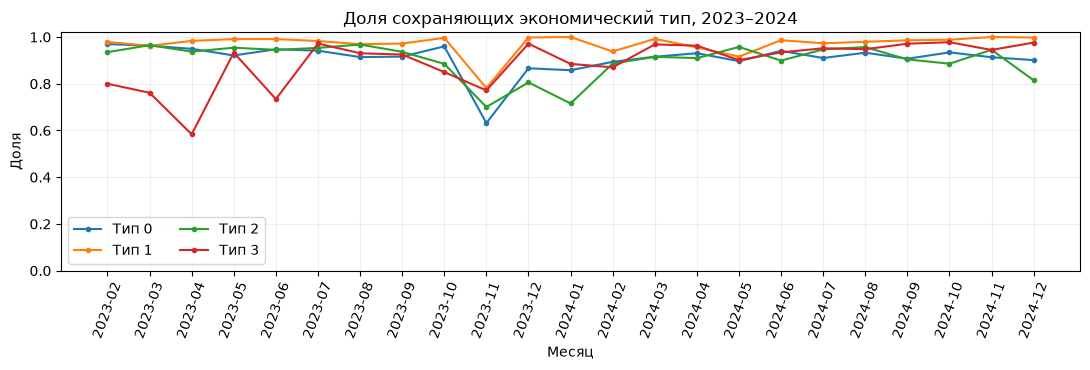

In [7]:
stability = snapshot_stability(aligned,months)
assoc, by_municipality = delta_switch_association(aligned,X_delta,months,year=2024)
retained = retained_delta_by_type(aligned,X_delta,*[m for m,_ in snapshots])
print('Устойчивость типов:')
display(stability.groupby('cluster').agg(median_stay=('stay_share','median'),
     worst_month_stay=('stay_share','min'),month_pairs=('stay_share','size')).round(3))
print('Связь переходов с годовыми изменениями:')
display(assoc[['indicator','n_available','missing_share','n_switchers',
   'median_delta_switchers','median_delta_non_switchers',
   'spearman_switch_count_delta','spearman_switch_count_abs_delta']].round(3))
print('Медианные годовые изменения среди сохраняющих экономический тип:')
display(retained.pivot(index='cluster',columns='indicator',values='median_delta').round(3))

fig,ax=plt.subplots(figsize=(11,3.8))
for cluster,part in stability.groupby('cluster'):
    part=part.sort_values('month_to')
    ax.plot(part.month_to,part.stay_share,marker='.',label=f'Тип {cluster}')
ax.set(title='Доля сохраняющих экономический тип, 2023–2024',
       ylabel='Доля',xlabel='Месяц',ylim=(0,1.02))
ax.tick_params(axis='x',rotation=70)
ax.grid(alpha=.2)
ax.legend(ncol=2)
plt.tight_layout();plt.show()

## 9. Доступность рынков и экономико-географическое положение (2024)

Индекс `market_access` СберИндекса отражает потенциальный объём внешних рынков, доступных муниципалитету: чем он выше, тем выгоднее положение относительно крупных потребительских рынков. Он рассчитан **за 2024 год**, нормирован на интервал от 0 до 1000 и не является показателем величины фактических товарных потоков или отраслевой специализации.

$$
MA_i = \operatorname{norm}_{[0,1000]}\left(\sum_{j\ne i}\frac{N_j}{\tau_{ij}}\right),
$$

где $N_j$ — население муниципалитета $j$, $\tau_{ij}$ — расстояние между муниципалитетами, а $\operatorname{norm}_{[0,1000]}$ — нормировка СберИндекса.

Для каждого типа $a$ на срезе **декабрь 2024** рассчитываем медиану $m_a$, первый и третий квартили, число доступных наблюдений и отличие от общей выборки:

$$
D_a^{(MA)}=\frac{m_a-m_{\mathrm{all}}}{Q_{0.75}(MA)-Q_{0.25}(MA)}.
$$

Если общий межквартильный размах равен нулю, стандартизированное отличие не определяется. В качестве сводной **описательной меры разделения** используем долю межкластерной вариации рангов:

$$
\eta^2_{\mathrm{rank}}=\frac{\sum_a n_a(\overline R_a-\overline R)^2}{\sum_{i\in O}(R_i-\overline R)^2},
$$

где $O$ — множество МО с известным значением индекса, $R_i$ — ранг индекса муниципалитета $i$ среди наблюдаемых, $n_a$ и $\overline R_a$ — количество наблюдений и средний ранг в типе. Значение показывает силу описательной связи, **не причинный эффект и не внешнюю валидацию отраслевой специализации**.

Источник: подготовленный на этапе 01 файл `outputs/base/X_market_access.parquet`. Пропуски сохраняются. Сопоставление с декабрём 2023 года не выполняется, поскольку индекс относится к 2024 году. Существующие кластерные метки и названия типов **не изменяются автоматически**.

Покрытие и межкластерная дифференциация индекса:


,month,municipalities,observed,coverage,n_clusters,global_median,global_iqr,rank_eta_squared
0,2024-12,2016,2004,0.994,4,323.25,115.275,0.156


,cluster,cluster_size,observed,coverage,median,q25,q75,contrast
0,0,651,651,1.000,314.30,260.70,351.950,-0.078
1,1,455,450,0.989,406.00,324.05,598.425,0.718
2,2,334,334,1.000,325.75,260.25,355.325,0.022
3,3,576,569,0.988,301.10,219.60,342.900,-0.192


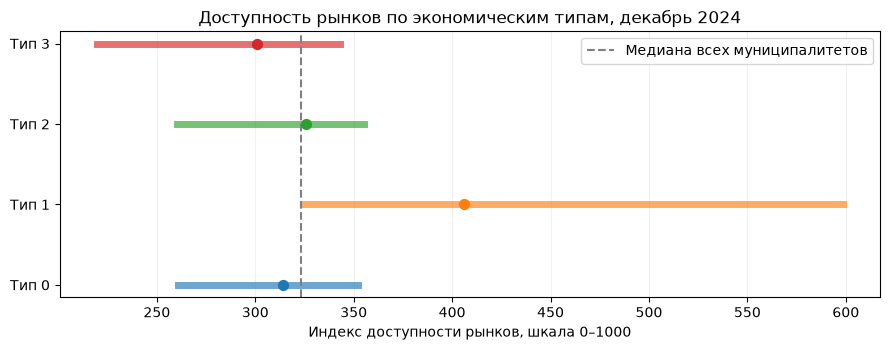

In [8]:
import importlib
import src.economic_interpretation as ei
importlib.reload(ei)
from src.economic_interpretation import market_access_profile, describe_market_access_2024

market_path = ROOT / icfg.get('market_access_2024_path', 'outputs/base/X_market_access.parquet')
if not market_path.is_file():
    raise FileNotFoundError(f'Не найдена подготовленная матрица этапа 01: {market_path}')

X_market_access = pd.read_parquet(market_path)
market_profiles, market_diagnostics = market_access_profile(X_market_access, aligned, '2024-12')
market_table = market_profiles[['cluster', 'cluster_size', 'observed', 'coverage',
                                'median', 'q25', 'q75', 'contrast']].sort_values('cluster')
print('Покрытие и межкластерная дифференциация индекса:')
display(market_diagnostics.round(3))
display(market_table.round(3))

fig, ax = plt.subplots(figsize=(9, 3.6))
for r in market_table.itertuples():
    if pd.notna(r.median):
        ax.plot([r.q25, r.q75], [r.cluster, r.cluster], lw=5, alpha=.65)
        ax.scatter(r.median, r.cluster, s=50, zorder=3)
ax.axvline(float(market_diagnostics.global_median.iloc[0]), ls='--', c='grey',
           label='Медиана всех муниципалитетов')
ax.set(yticks=market_table.cluster, yticklabels=[f'Тип {k}' for k in market_table.cluster],
       xlabel='Индекс доступности рынков, шкала 0–1000',
       title='Доступность рынков по экономическим типам, декабрь 2024')
ax.legend(loc='best')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

profiles = pd.concat([
    profiles.loc[profiles.family != 'market_access_2024'], market_profiles,
], ignore_index=True)
market_context = market_profiles.set_index('cluster')
candidate_types = candidate_types.drop(columns=[
    'market_access_median_2024', 'market_access_contrast_iqr_2024',
    'market_access_coverage_2024',
], errors='ignore')
candidate_types['market_access_median_2024'] = candidate_types.cluster.map(market_context['median'])
candidate_types['market_access_contrast_iqr_2024'] = candidate_types.cluster.map(market_context['contrast'])
candidate_types['market_access_coverage_2024'] = candidate_types.cluster.map(market_context['coverage'])

# Дополним интерпретацию отдельным географическим атрибутом.
# Потребительские/годовые характеристики и названия типов не изменяются.
market_context_table, market_conclusion_md = describe_market_access_2024(
    market_profiles, market_diagnostics)
market_context_by_cluster = market_context_table.set_index('cluster')['market_access_context_2024']
candidate_types['market_access_context_2024'] = candidate_types.cluster.map(market_context_by_cluster)
candidate_types['economic_profile_extended_2024'] = (
    'Потребительская структура: ' + candidate_types['consumer_contrasts_pp'].fillna('') +
    '; годовые показатели: ' + candidate_types['annual_contrasts_iqr'].fillna('') +
    '; доступность рынков: ' + candidate_types['market_access_context_2024'].fillna('')
)


In [9]:
from IPython.display import Markdown

# Заключение формируется из РЕАЛЬНЫХ рассчитанных значений market_access.
# Никаких заранее заданных направлений контрастов по четырём типам нет.
display(Markdown(market_conclusion_md))
print('Экономико-географический контекст включён в интерпретацию каждого типа:')
display(candidate_types[['cluster', 'market_access_median_2024',
                         'market_access_coverage_2024', 'market_access_contrast_iqr_2024',
                         'market_access_context_2024']].round(3))


### Фактические результаты по доступности рынков (декабрь 2024)

Охват индекса: **2004 из 2016** муниципалитетов (**99.4%**). Общая медиана: **323.2** (шкала 0–1000).

- **Тип 0.** Медиана индекса 314.3, интерквартильный интервал [260.7; 352.0]; ниже общей медианы (разность -8.9; -0.08 общего IQR); покрытие 651/651 (100.0%).
- **Тип 1.** Медиана индекса 406.0, интерквартильный интервал [324.1; 598.4]; выше общей медианы (разность +82.8; +0.72 общего IQR); покрытие 450/455 (98.9%).
- **Тип 2.** Медиана индекса 325.8, интерквартильный интервал [260.2; 355.3]; выше общей медианы (разность +2.5; +0.02 общего IQR); покрытие 334/334 (100.0%).
- **Тип 3.** Медиана индекса 301.1, интерквартильный интервал [219.6; 342.9]; ниже общей медианы (разность -22.1; -0.19 общего IQR); покрытие 569/576 (98.8%).

**Сравнение типов.** Наименьшая медиана у типа **3** (301.1), наибольшая — у типа **1** (406.0); разность составляет **104.9** пункта индекса.
Межтиповая доля вариации **рангов** индекса \(\eta^2_{\mathrm{rank}}=0.156\). Это мера описательного различия, а не причинный эффект.

**Интерпретация.** Эти цифры дополняют описание потребительских типов их экономико-географическим положением. Индекс за 2024 год не участвовал в обучении, не характеризует фактические потоки и не доказывает отраслевую специализацию.

Экономико-географический контекст включён в интерпретацию каждого типа:


,cluster,market_access_median_2024,market_access_coverage_2024,market_access_contrast_iqr_2024,market_access_context_2024
0,0,314.30,1.000,-0.078,"Медиана индекса 314.3, интерквартильный интерв..."
1,1,406.00,0.989,0.718,"Медиана индекса 406.0, интерквартильный интерв..."
2,2,325.75,1.000,0.022,"Медиана индекса 325.8, интерквартильный интерв..."
3,3,301.10,0.988,-0.192,"Медиана индекса 301.1, интерквартильный интерв..."


### 9.1. Обновлённая экономическая интерпретация

**Числовые научные выводы выводятся автоматически в предыдущей ячейке** из фактического `X_market_access.parquet`, поэтому они не подменены предположениями в статическом Markdown. По каждому типу показаны медиана, IQR, покрытие, направление и величина отличия от общей выборки. Затем указаны крайние типы и показатель межтиповой дифференциации $\eta^2_{\mathrm{rank}}$.

Новая информация добавляется к уже вычисленным потребительским и годовым профилям в `candidate_types.market_access_context_2024` и `candidate_types.economic_profile_extended_2024`. При сохранении она войдёт в `cluster_interpretations.parquet`, а `market_access_2024` — в `economic_profiles.parquet`.

**Важно:** изменение интерпретации не означает изменения состава кластеров или ранее согласованных названий. Для этой версии индекса есть только срез 2024 года; не приписываем его 2023 году. Обнаруженная связь с типами будет описательной, а не причинной.


## 10. Методологические ограничения и фиксация результатов

- **Объект интерпретации — тип потребительской структуры.** Описательные названия не обозначают доказанную отраслевую специализацию или причинный механизм.
- **Годовой контекст БДМО рассматривается ретроспективно.** Показатели 2024 года не используются для создания графов или меток за месяцы 2024 года.
- **Сопоставление муниципалитетов проверено.** Для декабрьского среза 2024 года использован справочник `municipality_lookup_2024.csv`; для всех 16 репрезентативных примеров указаны название и регион. Он не заменяет исторический справочник на каждую дату.
- **Пропуски БДМО сохраняются.** Медианы и нормированные отличия годовых признаков рассчитаны по доступным наблюдениям; типичность примеров определена только расстоянием в месячном CLR-пространстве.
- **Типы сопоставлены во времени**, но устойчивость номера кластера не гарантирует тождественности его экономического профиля на всех датах.

После научной проверки заключительная кодовая ячейка фиксирует четыре описательных названия, проверяет полноту таблицы представителей и сохраняет только три компактных Parquet-файла. Сохранение следует запускать один раз в пользовательской среде при `interpretation_10.save_enabled = true`.

- **Индекс доступности рынков относится к 2024 году.** Его использование в разделе 9 — ретроспективное сопоставление с типами декабря 2024, а не дополнительный признак обучения.


**Проверка представителей перед сохранением.** Проверенные примеры для четырёх типов выбираются
из `data/municipality_lookup_2024.csv` по `territory_id`; поле `oktmo` не
используется как ключ матрицы признаков. Если в старом сеансе переменная
`examples` осталась пустой из-за неоднозначного выбора ID, ячейка сохранения
построит представителей заново, не меняя метки и рассчитанные профили.
При отсутствии справочника сохранение останавливается с указанием нужного файла.


In [10]:
# Окончательная фиксация экономической типологии и сохранение трёх таблиц.
# Модели, графы и исходные данные повторно не рассчитываются.

TYPE_NAMES = {
    0: 'Продовольственно-ориентированный с умеренно пониженной деловой активностью',
    1: 'Высокоплотный с повышенной оплатой труда и долей прочих расходов',
    2: 'Продовольственно-маркетплейсный с пониженными годовыми показателями',
    3: 'Промежуточный потребительский с умеренно повышенной занятостью',
}

# Не разрешаем считать этап обновлённым, если раздел market_access не был выполнен.
if ('market_access_context_2024' not in candidate_types.columns or
    not profiles.family.eq('market_access_2024').any()):
    raise RuntimeError('Сначала выполните расчёт и выводы раздела 9 по market_access')

expected_ids = set(TYPE_NAMES)
actual_ids = set(candidate_types['cluster'].astype(int))
if actual_ids != expected_ids or candidate_types['cluster'].duplicated().any():
    raise ValueError(f'Неожиданный состав типов: {actual_ids}')

# Если запускалась только новая секция 9 или раньше не удалось прочитать
# справочник (старый конфиг неоднозначно выбирал territory_id / oktmo),
# восстанавливаем именно проверенных представителей. Новые кластеры не обучаем.
if 'examples' not in globals() or examples is None or examples.empty:
    verified_lookup_path = ROOT / 'data' / 'municipality_lookup_2024.csv'
    if not verified_lookup_path.is_file():
        raise FileNotFoundError(
            'Нет представителей и проверенного справочника '
            f'{verified_lookup_path}. Сначала поместите сюда '
            'municipality_lookup_2024.csv и выполните раздел 7.'
        )
    print('Таблица представителей пуста: восстанавливаю её из проверенного справочника 2024.')
    verified_lookup = read_municipality_lookup(
        verified_lookup_path, X_dynamic.index,
        id_col='territory_id', name_col='municipality_name', region_col='region',
    )
    examples = representative_municipalities(
        X_dynamic, mapping, aligned, icfg['representatives_month'],
        verified_lookup, X_annual,
        top_n=icfg['representatives_per_cluster'], zero_floor=cfg['zero_floor'],
    )
    print('Восстановлено представителей:', len(examples))

expected_representatives = len(expected_ids) * int(icfg['representatives_per_cluster'])
if len(examples) != expected_representatives:
    raise ValueError(
        f'Ожидалось {expected_representatives} проверенных представителей; '
        f'получено {len(examples)}. Выполните раздел 7 заново.'
    )
if set(examples['cluster'].astype(int)) != expected_ids:
    raise ValueError('Таблица представителей не охватывает все типы')
if examples['municipality_id'].astype(str).duplicated().any():
    raise ValueError('ID представителей не должны повторяться')
if examples[['municipality_name', 'region']].isna().any().any():
    raise ValueError('В таблице представителей отсутствуют названия или регионы')
if not (examples.groupby('cluster').size() == icfg['representatives_per_cluster']).all():
    raise ValueError('Для некоторых типов число представителей не соответствует конфигурации')

candidate_types = candidate_types.copy()
candidate_types['economic_type_name'] = candidate_types['cluster'].map(TYPE_NAMES)
candidate_types = candidate_types.drop(columns=['provisional_name'], errors='ignore')
candidate_types['interpretation_status'] = 'reviewed'

if not icfg.get('save_enabled', False):
    raise RuntimeError(
        'Установите interpretation_10.save_enabled = true в '
        'configs/clustering_experiment.json и повторно выполните первую и эту ячейки.'
    )

paths = save_tables(ROOT / icfg['output_directory'], profiles, candidate_types, examples)
print('Сохранены итоговые таблицы, включая market_access за 2024 год:')
for path in paths:
    print('-', path.relative_to(ROOT))
display(candidate_types[['cluster', 'economic_type_name', 'n_municipalities', 'interpretation_status']])


Сохранены итоговые таблицы, включая market_access за 2024 год:
- outputs/bdmo_v3/interpretation_step10/economic_profiles.parquet
- outputs/bdmo_v3/interpretation_step10/cluster_interpretations.parquet
- outputs/bdmo_v3/interpretation_step10/typical_municipalities.parquet


,cluster,economic_type_name,n_municipalities,interpretation_status
0,0,Продовольственно-ориентированный с умеренно по...,651,reviewed
1,1,Высокоплотный с повышенной оплатой труда и дол...,455,reviewed
2,2,Продовольственно-маркетплейсный с пониженными ...,334,reviewed
3,3,Промежуточный потребительский с умеренно повыш...,576,reviewed


## 11. Окончательные научные выводы

### 11.1. Достоверность и границы исследования

Рассмотрены **2016 муниципалитетов**, **24 месяца** (январь 2023 — декабрь 2024 года) и **четыре согласованных во времени типа** модели Temporal K-Means ($\lambda=0{,}25$). Основа модели — шесть месячных категорий потребительских расходов; внешние характеристики для интерпретации — восемь годовых показателей БДМО за 2023 и 2024 годы и **индекс доступности рынков СберИндекса за 2024 год**. Ни графы, ни кластерные метки в этом этапе не переобучались. Индекс не был входным признаком Temporal K-Means.

Контроль `X_delta` подтвердил для каждого из восьми признаков формулу $\Delta A_i=A_{i,2024}-A_{i,2023}$, в том числе сохранение маски пропусков. В предоставленном запуске все десять вычислительных ячеек завершились без исключений, в том числе расчёт `market_access` и итоговое сохранение. **Справочник идентификаторов теперь корректно подключён**: в таблице представителей имеются названия, регионы и CLR-расстояния для 16 муниципалитетов. Следовательно, прежний вывод об отсутствии географической идентификации больше не актуален.

### 11.2. Экономические типы по декабрю 2024 года

Названия в таблице являются **описательной интерпретацией наблюдаемых признаков**, а не утверждением отраслевой специализации. Для долей расходов указано отличие среднего типа от среднего всех муниципалитетов **в процентных пунктах (п.п.)**; для БДМО — отличие медианы типа от общей медианы **в единицах межквартильного размаха (IQR)**.

| Тип | Утверждаемое описательное название | МО | Потребительские особенности | Годовой социально-экономический контекст |
|---|---|---:|---|---|
| **0** | **Продовольственно-ориентированный с умеренно пониженной деловой активностью** | **651** | Продукты **+3,12 п.п.**; маркетплейсы **+1,80**; прочие расходы **−2,77** | Организации на 1000 жителей **−0,22 IQR**, доля прибыльных организаций **−0,21**, оплата труда **−0,20** |
| **1** | **Высокоплотный с повышенной оплатой труда и долей прочих расходов** | **455** | Продукты **−8,02 п.п.**; прочие расходы **+6,11**; маркетплейсы **−3,23** | Плотность населения **+19,22 IQR**, организации на 1000 жителей **+1,77**, оплата труда **+1,47** |
| **2** | **Продовольственно-маркетплейсный с пониженными годовыми показателями** | **334** | Продукты **+4,84 п.п.**; маркетплейсы **+3,15**; прочие расходы **−5,34** | Оплата труда **−0,38 IQR**, доля прибыльных организаций **−0,35**, число организаций **−0,28** |
| **3** | **Промежуточный потребительский с умеренно повышенной занятостью** | **576** | Прочие расходы **+1,41 п.п.**; маркетплейсы **−1,31**; здоровье **−0,24** | Занятые на 1000 жителей **+0,27 IQR**, торговые площади на жителя **+0,20**, оплата труда **+0,18** |

Типы **0 и 2** имеют повышенную долю продовольственных и маркетплейсных расходов, но у **типа 2** отличия выражены сильнее и более заметно снижение годовых показателей. **Тип 1** отличается и составом расходов, и значительно более высокой плотностью населения. **Тип 3** занимает промежуточное положение по потребительскому профилю, с умеренно повышенными показателями занятости и торговой инфраструктуры.

Контраст плотности **+19,22 IQR** означает большое отклонение относительно сравнительно узкого общего межквартильного интервала; это **не** означает увеличение плотности населения в 19 раз. На тепловой карте цвета ограничены диапазоном $[-3,3]$, тогда как исходные значения в таблицах сохранены без усечения.

### 11.3. Масштаб экономических различий и полнота БДМО

В декабре 2024 года медиана `wage` для типа 1 составляет **114 799,4**, для типа 2 — **47 940,3** (отношение примерно **2,4**). Медиана `reporting_companies_per_1000` равна соответственно **15,069** и **3,408** (отношение примерно **4,4**). Это значительные различия в наблюдаемых уровнях показателей; они не устанавливают статистическую или причинную значимость. Для `wage` точную единицу измерения следует брать из исходного словаря БДМО, не угадывая её по числу.

Минимальное покрытие **отдельного** годового признака в декабре 2024 года равно **88,9%** для типа 0, **75,8%** для типа 1, **91,0%** для типа 2 и **89,9%** для типа 3. Пропуски не заменялись нулями: характеристики БДМО рассчитаны по доступным наблюдениям, что ограничивает сопоставимость некоторых характеристик.

### 11.4. Проверенные типичные муниципалитеты

По расстоянию до CLR-центроида *внутри каждого типа* выбрано по четыре представителя (16 всего). Первая пара каждого типа:

| Тип | Наиболее близкие к центроиду муниципалитеты (декабрь 2024) |
|---|---|
| **0** | **Данковский муниципальный район** (Липецкая область, ID 1414); **городской округ город Шарья** (Костромская область, ID 1308) |
| **1** | **Внутригородские территории Москвы** (ID **2546** и **2467**, два наиболее близких представителя типа); ещё два московских представителя имеют ID **2466** и **2469** |
| **2** | **Кривошеинский муниципальный район** (Томская область, ID 2156); **Измалковский муниципальный район** (Липецкая область, ID 1420) |
| **3** | **Давлекановский муниципальный район** (Республика Башкортостан, ID 49); **городской округ город Лесосибирск** (Красноярский край, ID 675) |

Полные 16 строк, включая все проверенные названия, регионы, годовые характеристики и расстояния, представлены в output раздела 7 и предназначены для `typical_municipalities.parquet`. У Измалковского района отсутствуют некоторые годовые показатели: это **не ошибка выбора**, так как типичность определяется по потребительским долям. То, что все четыре наиболее типичных представителя типа 1 относятся к Москве, **не доказывает**, что весь тип ограничен Москвой.

### 11.5. Временная динамика типов

| Тип | МО в декабре 2023 | МО в декабре 2024 | Разность | Медианная доля сохранения метки между соседними месяцами |
|---|---:|---:|---:|---:|
| 0 | 654 | 651 | −3 | **91,6%** |
| 1 | 481 | 455 | −26 | **98,3%** |
| 2 | 334 | 334 | 0 | **93,5%** |
| 3 | 547 | 576 | +29 | **93,3%** |

**Наиболее устойчив тип 1**: медианное сохранение метки составляет **98,3%** по 23 последовательным месячным переходам, минимальное — **78,1%**. Минимальные значения для типов 0, 2 и 3: **63,1%**, **70,0%** и **58,4%** соответственно. Нулевая разность численности типа 2 между декабрьскими срезами не исключает входящие и исходящие переходы отдельных муниципалитетов.

Метки были согласованы во времени, поэтому перестановка произвольных номеров типов не интерпретируется как экономический переход. Вместе с тем **состав групп меняется**; различия годовых профилей между декабрьскими срезами могут отражать и изменение состава, и изменение самих муниципалитетов. Поэтому в ноутбуке отдельно рассчитаны годовые изменения для муниципалитетов, сохранивших декабрьскую метку.

### 11.6. Связь переходов с годовыми изменениями БДМО

Количество смен типов в 2024 году сопоставлено с восемью годовыми изменениями. Для оплаты труда корреляция Спирмена числа смен с самой разностью **$\rho=-0{,}200$**; для *модуля* изменения плотности населения **$\rho=-0{,}279$**, для *модуля* изменения доли прибыльных организаций **$\rho=0{,}187$**. Абсолютные величины умеренны или малы: данные **не подтверждают** универсальной положительной связи между силой годового изменения и числом смен типа.

В частности, медианная разность `wage` у муниципалитетов с хотя бы одной сменой типа за 2024 год равна **+8 872,2**, без смен — **+10 676,5** (единицы исходного показателя). Периодичность БДМО — годовая, а переходов — месячная; эти связи **описательные**, не причинные и не помесячные.

### 11.7. Научный итог и передаваемые результаты

Результаты подтверждают **неоднородность потребительских структур муниципалитетов России** и их сопоставление с различиями в доступных годовых экономических характеристиках. Четыре типа различаются долями категорий расходов, медианной оплатой труда, распространённостью организаций, плотностью населения и устойчивостью экономических меток. **Добавление независимого от процедуры кластеризации индекса `market_access` выявило различия также по потенциальной доступности внешних рынков** (см. § 11.8). Названия типов зафиксированы **как описательные**, без недоказанных определений «промышленный», «аграрный», «туристический» или «инновационный».

В выполненном ноутбуке **последняя кодовая ячейка успешно завершила сохранение** трёх файлов в `outputs/bdmo_v3/interpretation_step10/`:

- `economic_profiles.parquet` — потребительские и годовые профили, а также отдельный профиль `market_access_2024`;
- `cluster_interpretations.parquet` — утверждённые названия, расширенное экономико-географическое описание, значения `market_access` и статус `reviewed`;
- `typical_municipalities.parquet` — 16 представителей с проверенными названиями и регионами.

**Статус:** результаты этапа 10 рассчитаны и, согласно выводу выполненной ячейки, записаны на диск в среде запуска. Ни повторное обучение, ни перезапуск этапов 11–12 для этой внешней интерпретации не нужны.


### 11.8. Экономико-географическая интерпретация на основе индекса доступности рынков

Выполнен отдельный анализ **индекса доступности рынков СберИндекса (`market_access`) за 2024 год**, который описывает потенциальный объём внешних рынков, доступных муниципалитету с учётом численности населения других территорий и расстояний до них. Высокий индекс означает более благоприятное экономико-географическое положение относительно крупных потребительских рынков, **но не измеряет фактический товарооборот или экономическую специализацию**. Сопоставление проведено с готовыми типами на срезе **декабрь 2024 года**.

Индекс доступен для **2004 из 2016 муниципалитетов (99,4%)**, общая медиана — **323,25** по нормированной шкале 0–1000, общий межквартильный размах — **115,275**. Все пропуски оставлены как пропуски.

| Тип | Доступно / всего МО | Медиана `market_access` | Межквартильный интервал Q25–Q75 | Отклонение медианы от общей, пункты | Отклонение в единицах общего IQR |
|---|---:|---:|---:|---:|---:|
| **0** | 651 / 651 | **314,30** | 260,70–351,95 | −8,95 | −0,078 |
| **1** | 450 / 455 | **406,00** | 324,05–598,43 | **+82,75** | **+0,718** |
| **2** | 334 / 334 | **325,75** | 260,25–355,33 | +2,50 | +0,022 |
| **3** | 569 / 576 | **301,10** | 219,60–342,90 | **−22,15** | **−0,192** |

Максимальная разница медиан наблюдается между **типом 1 и типом 3**: **104,90 пункта индекса**. Описательная доля межтиповой вариации **рангов** составляет $\eta^2_{\mathrm{rank}}=0{,}156$. Показатель свидетельствует о различиях распределений индекса между типами, но **не означает**, что кластерная принадлежность объясняет 15,6% причинных изменений доступности рынков или 15,6% вариации исходного ненормированного индекса.

**Уточнение содержательной интерпретации четырёх типов:**

- **Тип 0 — продовольственно-ориентированный с умеренно пониженной деловой активностью.** Медианная доступность рынков немного ниже общей (314,30 против 323,25). Экономико-географический контекст не формирует здесь столь же выраженного контраста, как у типа 1. Называть тип 0 территориально изолированным по этим данным нельзя.
- **Тип 1 — высокоплотный с повышенной оплатой труда и долей прочих расходов.** **Наиболее выраженное дополнение к интерпретации:** медиана индекса 406,00, превышение общей медианы на 82,75 пункта, верхний квартиль достигает 598,43. Повышенная доступность крупных рынков согласуется с высокой плотностью населения, деловой активностью и структурой расходов, отличающейся повышенной долей «прочих». Таким образом, для типа 1 обоснованно отмечать **более выгодное экономико-географическое положение**, а не только особенности потребления и БДМО.
- **Тип 2 — продовольственно-маркетплейсный с пониженными годовыми показателями.** Медиана 325,75 практически совпадает с общей (разница +2,50); индекс не выявляет самостоятельного яркого пространственного отличия этого типа. По имеющемуся результату нельзя объяснять его продовольственно-маркетплейсную структуру слабой или особенно высокой доступностью рынков.
- **Тип 3 — промежуточный потребительский с умеренно повышенной занятостью.** Медиана 301,10 — **самая низкая среди четырёх типов**, на 22,15 пункта ниже общей. Это позволяет дополнить описание типа относительно менее выгодным положением по доступности внешних рынков, но не утверждать, что все его муниципалитеты периферийны: распределения типов существенно перекрываются.

**Может ли доступность рынков влиять на формирование потребительского типа?** В *экономическом* смысле это **правдоподобная, но пока не проверенная причинная гипотеза**. Близость крупных рынков потенциально связана с ассортиментом товаров и услуг, развитием торговой инфраструктуры и транспортно-логистическими возможностями. Такие условия могут сопровождаться изменениями структуры расходов. Особенно содержательна эта гипотеза **для типа 1**, у которого одновременно наблюдаются высокие `market_access`, плотность населения, оплата труда и доля прочих расходов. У типа 3 противоположное по уровню индекса положение может отражать иной экономико-географический контекст.

При этом есть три принципиальных ограничения:

1. **Алгоритмического влияния на четыре типа не было.** `market_access` не подавался на вход CLR-преобразования, построения графа, K-Means или Temporal K-Means. Поэтому индекс **не определял присвоение меток** и не служит доказательством, что добавление его в модель улучшит кластеризацию.
2. **Нельзя отделить самостоятельную роль доступности от урбанизации и регионального положения.** Тип 1 имеет высокую плотность и оплату труда; все четыре ближайших к CLR-центроиду представителя типа 1 относятся к Москве. Это указывает на возможное смешение пространственного эффекта с характеристиками крупных городских агломераций, но не доказывает, что весь тип представлен Москвой. Для вывода о независимом влиянии индекса нужен отдельный анализ с контролем плотности населения, региона и иных факторов.
3. **Данные описательные и относятся к одному году.** Индекс за 2024 год сопоставлен с декабрьскими метками 2024 года; временной порядок и механизм воздействия не установлены. Медианные различия и $\eta^2_{\mathrm{rank}}$ не являются оценкой причинного эффекта. Приписывать им объяснение переходов типов в 2023 году также некорректно.

**Научный вывод:** `market_access` заметно **усиливает интерпретируемость прежде всего типа 1**, позволяя характеризовать его как группу с наиболее высокой потенциальной доступностью внешних рынков. Для типа 3 фиксируется противоположный относительный контекст. Для типов 0 и 2 индекс не даёт сопоставимо сильного разграничения. Следовательно, типология потребления **ассоциирована с экономико-географическим положением**, но сама по себе не устанавливает ни причинного влияния индекса на потребление, ни необходимости пересматривать четыре утверждённых типа.
